In [4]:
import os

print("Tamanho do arquivo:")
print(os.path.getsize("/content/ev_battery_failure_dataset.csv"))

print("\nPrimeiras linhas:")
print(pd.read_csv("/content/ev_battery_failure_dataset.csv", nrows=3))

print("\nÚltimas linhas:")
df_temp = pd.read_csv("/content/ev_battery_failure_dataset.csv")
print(df_temp.tail())

print("\nDimensão:")
print(df_temp.shape)

Tamanho do arquivo:
77211206

Primeiras linhas:
  vehicle_id vehicle_brand vehicle_model vehicle_type  manufacturing_year  \
0   EV100000        Nissan          Leaf          SUV              2019.0   
1   EV100001          Audi        e-tron        Sedan              2018.0   
2   EV100002        Toyota          bZ4X          Van              2018.0   

  battery_manufacturer battery_chemistry  battery_capacity_kwh drive_type  \
0                 CATL               LMO                 82.54        RWD   
1          Samsung SDI               NaN                 64.17        AWD   
2              Guoxuan               NMC                 90.92        RWD   

   odometer_km  ...  sensor_fault_count BMS_warning_count  \
0      98163.0  ...                 2.0               3.0   
1     113600.0  ...                 0.0               3.0   
2     242253.0  ...                 4.0               1.0   

  abnormal_voltage_events  battery_stress_index  aging_score  \
0                     0.0

In [2]:
import os

print(os.path.exists("/content/ev_battery_failure_dataset.csv"))
print(os.path.getsize("/content/ev_battery_failure_dataset.csv"))

True
73400320


In [3]:
df_check = pd.read_csv("/content/ev_battery_failure_dataset.csv")

print("Dimensões:", df_check.shape)
print("Quantidade de veículos:", df_check['vehicle_id'].nunique())

Dimensões: (190129, 70)
Quantidade de veículos: 190129


# 03 — Análise para Regressão

Este notebook apresenta a análise do problema de regressão definido para o conjunto de dados de baterias de veículos elétricos.

A variável `predicted_remaining_life_cycles` foi selecionada como alvo, representando a estimativa da quantidade de ciclos restantes de vida útil da bateria. A análise busca investigar sua distribuição, variabilidade e relação com as demais características, fornecendo evidências para a seleção de atributos e de possíveis algoritmos de regressão.

## Definição do problema de regressão

O alvo selecionado foi `predicted_remaining_life_cycles`, uma variável numérica contínua relacionada à vida útil restante da bateria.

Os identificadores `vehicle_id` e `battery_serial` foram removidos da análise por não representarem características preditivas. Também foram removidos os registros sem valor para a variável-alvo, resultando em **191.026 observações** disponíveis para a análise de regressão.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/ev_battery_failure_dataset.csv")

print("Dimensões:", df.shape)
df.head()

Dimensões: (200000, 70)


,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,EV100000,Nissan,Leaf,SUV,2019.0,CATL,LMO,82.54,RWD,98163.0,...,2.0,3.0,0.0,0.0,53.5,66.0,65.2,0.0,401.0,0
1,EV100001,Audi,e-tron,Sedan,2018.0,Samsung SDI,NaN,64.17,AWD,113600.0,...,0.0,3.0,0.0,51.0,38.8,67.8,46.3,40.9,1094.0,0
2,EV100002,Toyota,bZ4X,Van,2018.0,Guoxuan,NMC,90.92,RWD,242253.0,...,4.0,1.0,0.0,36.2,66.1,48.6,0.0,6.5,645.0,0
3,EV100003,Volkswagen,ID.3,Hatchback,2022.0,CATL,NMC,47.35,AWD,83700.0,...,0.0,3.0,1.0,23.4,32.5,58.2,NaN,NaN,867.0,0
4,EV100004,Tesla,Model X,Crossover,2015.0,BYD Battery,NMC,68.04,FWD,88784.0,...,3.0,2.0,1.0,51.2,45.4,51.0,NaN,100.0,1090.0,0


In [6]:
# Alvo da regressão
target = 'predicted_remaining_life_cycles'

# Remover identificadores
df_reg = df.drop(columns=['vehicle_id', 'battery_serial']).copy()

# Remover apenas registros sem valor no alvo
df_reg = df_reg.dropna(subset=[target])

print("Dimensões do dataset de regressão:", df_reg.shape)
print("Alvo:", target)

Dimensões do dataset de regressão: (191026, 68)
Alvo: predicted_remaining_life_cycles


In [7]:
# Estatísticas do alvo da regressão
df_reg[target].describe()

,predicted_remaining_life_cycles
count,191026.000000
mean,1859.485986
std,1834.356925
min,0.000000
25%,891.000000
50%,1245.000000
75%,3085.000000
max,15474.000000


A distribuição de `predicted_remaining_life_cycles` não é uniforme e apresenta diferentes concentrações de observações. Também é possível observar um grupo menor de registros com valores elevados de vida útil restante.

Esse comportamento sugere que o alvo possui uma estrutura mais complexa do que uma distribuição aproximadamente normal e deve ser considerado na escolha e avaliação dos modelos de regressão.

In [8]:
print("Quantidade de valores distintos:", df_reg[target].nunique())

Quantidade de valores distintos: 5169


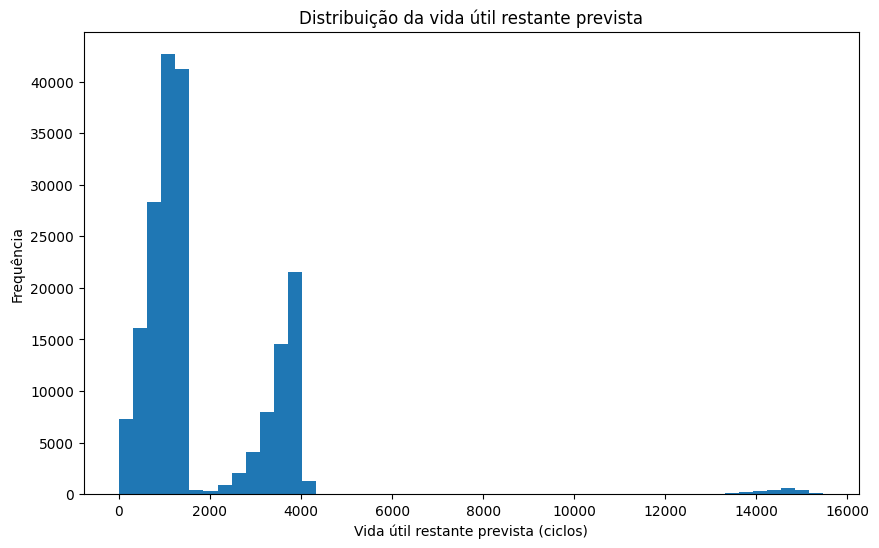

In [9]:
plt.figure(figsize=(10, 6))

plt.hist(df_reg[target], bins=50)

plt.xlabel('Vida útil restante prevista (ciclos)')
plt.ylabel('Frequência')
plt.title('Distribuição da vida útil restante prevista')

plt.show()

## Distribuição e variabilidade do alvo

A variável-alvo apresenta ampla variabilidade, com valores entre **0 e 15.474 ciclos**, média de aproximadamente **1.859,49 ciclos**, mediana de **1.245 ciclos** e **5.169 valores distintos**. Essa variabilidade torna a característica adequada para a formulação de um problema de regressão.

## Relação das características numéricas com o alvo

Para identificar características potencialmente relevantes para a regressão, foi calculada a correlação entre as variáveis numéricas e `predicted_remaining_life_cycles`.

In [10]:
# Correlação das variáveis numéricas com o alvo
corr_target = (
    df_reg
    .select_dtypes(include=np.number)
    .corr()[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

corr_target.head(15)

,predicted_remaining_life_cycles
cell_voltage_avg,-0.827021
thermal_runaway_risk,-0.736390
thermal_health_score,0.697731
capacity_loss_percent,-0.483810
battery_health_percent,0.483712
state_of_health,0.479289
aging_score,-0.416512
cell_voltage_std,-0.398392
charge_efficiency,0.360738
BMS_warning_count,-0.312779


As maiores correlações foram observadas para `cell_voltage_avg` (r = -0,827), `thermal_runaway_risk` (r = -0,736) e `thermal_health_score` (r = 0,698). Também foram observadas associações relevantes com características relacionadas à saúde e degradação da bateria.

Embora `battery_failure` apareça entre as variáveis correlacionadas ao alvo, ela não será considerada uma característica preditiva neste problema, pois foi definida como alvo do problema de classificação deste projeto.

## Análise gráfica das principais relações

As três características numéricas com maior correlação absoluta com o alvo foram analisadas por meio de gráficos de dispersão para verificar visualmente a direção e o comportamento dessas relações.

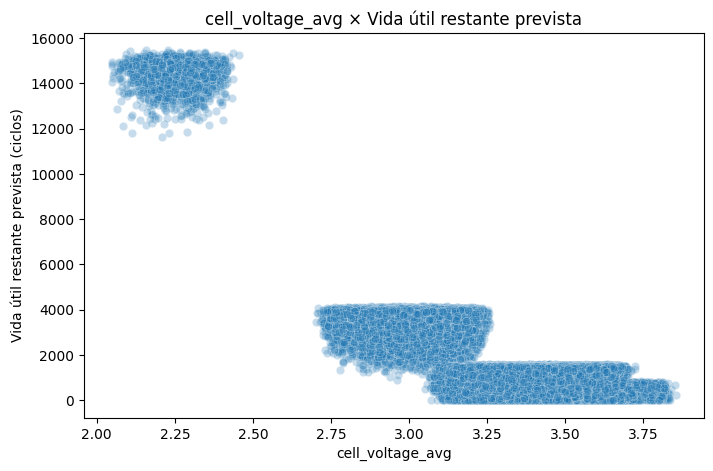

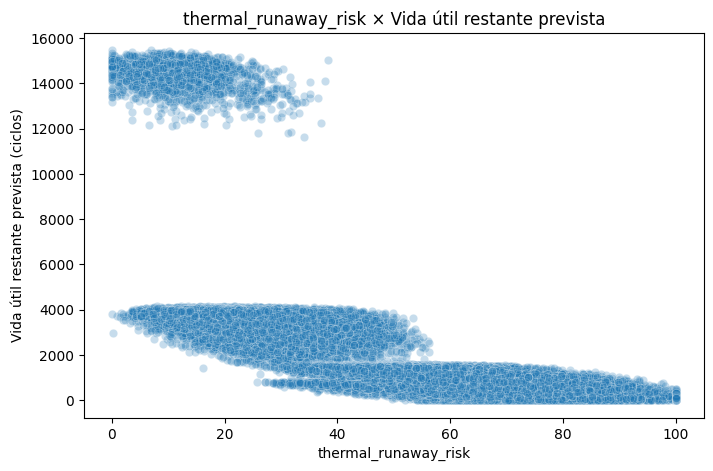

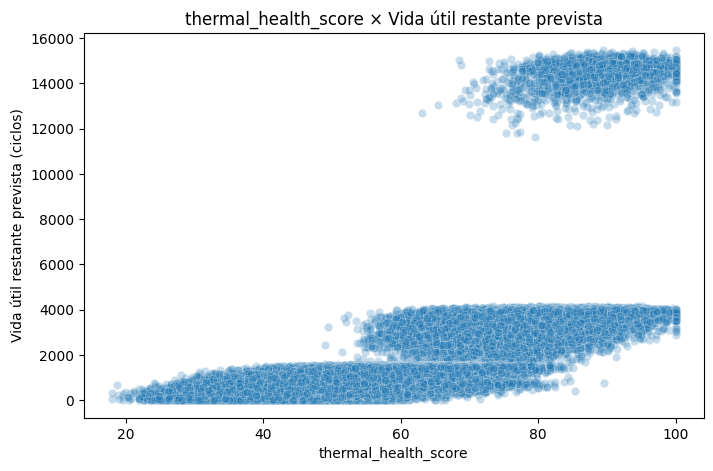

In [11]:
# Relações entre as principais variáveis e o alvo

features_top = [
    'cell_voltage_avg',
    'thermal_runaway_risk',
    'thermal_health_score'
]

for feature in features_top:
    plt.figure(figsize=(8, 5))
    sns.scatterplot(
        data=df_reg,
        x=feature,
        y=target,
        alpha=0.25
    )

    plt.xlabel(feature)
    plt.ylabel('Vida útil restante prevista (ciclos)')
    plt.title(f'{feature} × Vida útil restante prevista')

    plt.show()

Os gráficos confirmam uma relação negativa de `cell_voltage_avg` e `thermal_runaway_risk` com a vida útil restante prevista, enquanto `thermal_health_score` apresenta relação positiva.

Também são observados agrupamentos distintos de registros, indicando que as relações entre as características e o alvo não são estritamente lineares em todo o conjunto de dados.

## Seleção de características

Para a seleção das características potencialmente úteis ao problema de regressão, `battery_failure` foi excluída da lista de candidatas. As características restantes foram ordenadas de acordo com o valor absoluto de sua correlação com `predicted_remaining_life_cycles`.

In [12]:
# Seleção das características numéricas mais relacionadas ao alvo

corr_target = (
    df_reg.select_dtypes(include=np.number)
    .corr()[target]
    .drop(target)
    .sort_values(key=abs, ascending=False)
)

# battery_failure é o alvo do problema de classificação
# e não será utilizada como característica da regressão
corr_target = corr_target.drop(
    labels=['battery_failure'],
    errors='ignore'
)

corr_target.head(15)

,predicted_remaining_life_cycles
cell_voltage_avg,-0.827021
thermal_runaway_risk,-0.736390
thermal_health_score,0.697731
capacity_loss_percent,-0.483810
battery_health_percent,0.483712
state_of_health,0.479289
aging_score,-0.416512
cell_voltage_std,-0.398392
charge_efficiency,0.360738
BMS_warning_count,-0.312779


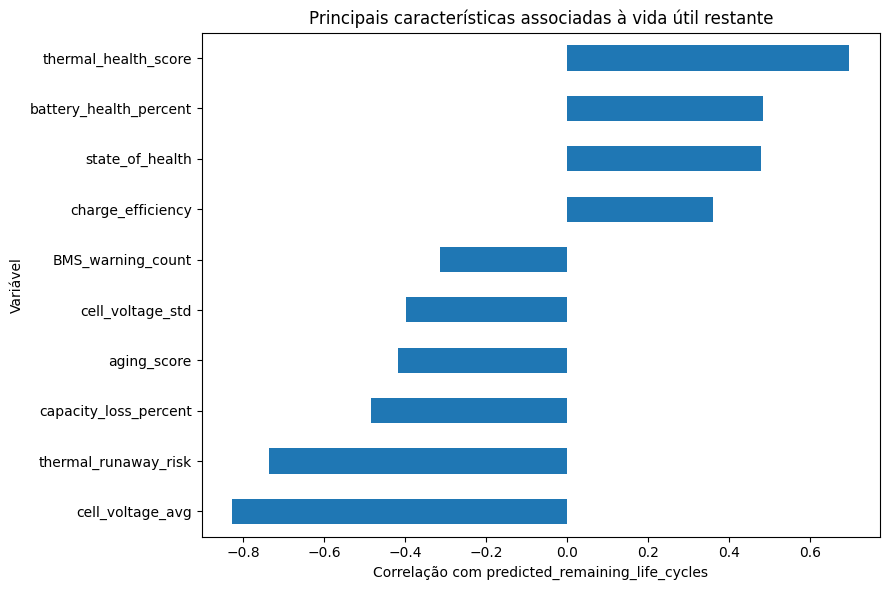

In [13]:
# Visualização das principais características associadas ao alvo

top_reg_features = corr_target.head(10).sort_values()

plt.figure(figsize=(9, 6))

top_reg_features.plot(kind='barh')

plt.xlabel('Correlação com predicted_remaining_life_cycles')
plt.ylabel('Variável')
plt.title('Principais características associadas à vida útil restante')

plt.tight_layout()
plt.show()

## Conclusões da análise de regressão

As análises indicam que características elétricas, térmicas e relacionadas à degradação apresentam forte relação com a vida útil restante prevista da bateria. Entre as principais características destacam-se `cell_voltage_avg`, `thermal_runaway_risk`, `thermal_health_score`, `capacity_loss_percent`, `battery_health_percent`, `state_of_health`, `aging_score`, `cell_voltage_std`, `charge_efficiency` e `BMS_warning_count`.

Entretanto, algumas dessas características apresentam forte multicolinearidade, especialmente `capacity_loss_percent`, `battery_health_percent` e `state_of_health`. Esse aspecto deve ser considerado na seleção definitiva dos atributos, principalmente em modelos lineares.

Entre os principais desafios estão a distribuição não uniforme do alvo, a presença de valores extremos, valores ausentes, multicolinearidade e relações que não se mostram estritamente lineares.

A **Regressão Linear** pode ser utilizada como modelo de referência pela simplicidade e interpretabilidade. Entretanto, devido aos padrões observados, modelos capazes de representar relações não lineares, como **Random Forest Regressor** e métodos de **Gradient Boosting**, também são candidatos adequados. Para comparação dos modelos, métricas como **MAE, RMSE e R²** são recomendadas.